# Step 0b - Feature + model search (best R^2)

Loop over **Linear / Ridge / Lasso** with **forward feature selection** on k-fold CV R^2,
to find the best feature set per target for **Kappa** and **Viscosity**.

- `feature_search.run_search()` returns a **leaderboard** (best CV R^2 first) + raw results.
- `exclude_effect=True` keeps only true setpoints, so R^2 reflects what operators can control.
- **Gate rule:** if the best CV R^2 is still low (< ~0.3), the surrogate is too weak - do NOT optimize.
- Read-only. Uses `data/batch_master.csv` via `build_master.load_outputs()`. No PI.

In [1]:
import matplotlib.pyplot as plt
import feature_search

df = feature_search.load_master()
print("batches (quality_flag == ok):", len(df))

leaderboard, results = feature_search.run_search(df, exclude_effect=True)
leaderboard

batches (quality_flag == ok): 1463


,target,model,cv_r2,cv_r2_std,n_features,n_effect,n
0,press1_kappa,linear,0.046,0.044,4,0,365
1,press1_kappa,ridge,0.046,0.044,4,0,365
2,press1_kappa,lasso,0.046,0.040,4,0,365
3,press1_viscosity,linear,0.204,0.062,2,0,447
4,press1_viscosity,ridge,0.204,0.062,2,0,447
5,press1_viscosity,lasso,0.204,0.062,2,0,447


In [2]:
# Best (model, feature-set) per target.
best = feature_search.best_per_target(results)
for t, r in best.items():
    print(f"{t}: cv_r2={r['cv_r2']} +/- {r['cv_r2_std']}  (n={r['n']}, {len(r['features'])} feats)")
    for f in r['features']:
        print(f"    - {f}")

press1_kappa: cv_r2=0.046 +/- 0.044  (n=365, 4 feats)
    - screen_diff_pressure_mean_heat_and_cook
    - alkali_accumulator1_conc_mean_hot_liquor_filling
    - circulation_temp_max_hot_liquor_filling
    - alkali_accumulator2_conc_mean_hot_liquor_filling
press1_viscosity: cv_r2=0.204 +/- 0.062  (n=447, 2 feats)
    - alkali_accumulator1_conc_mean_hot_liquor_filling
    - pfactor_setpoint_last_prehydrolysis


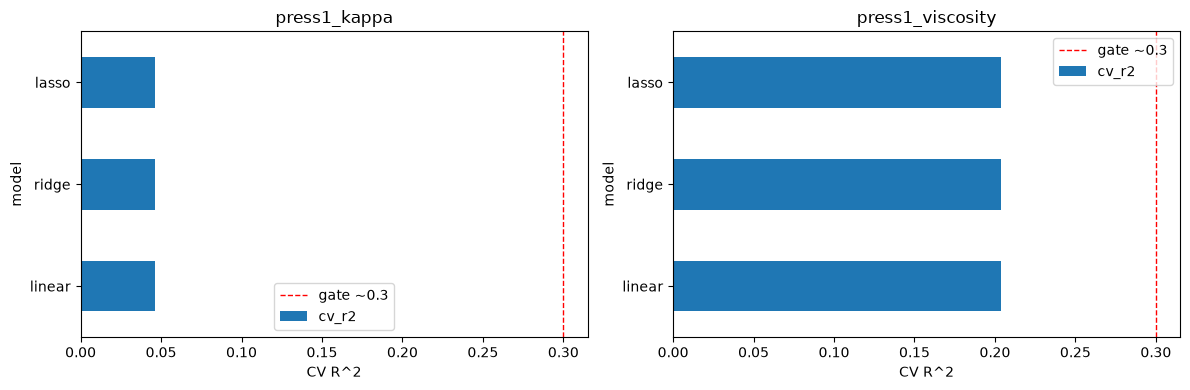

In [3]:
# CV R^2 per (target, model).
targets = list(results.keys())
fig, axes = plt.subplots(1, len(targets), figsize=(6 * len(targets), 4))
if len(targets) == 1:
    axes = [axes]
for ax, t in zip(axes, targets):
    sub = leaderboard[leaderboard['target'] == t].set_index('model')['cv_r2']
    sub.plot.barh(ax=ax)
    ax.axvline(0.3, color='red', ls='--', lw=1, label='gate ~0.3')
    ax.set_title(t)
    ax.set_xlabel('CV R^2')
    ax.legend()
plt.tight_layout()
plt.show()

## Read the result

- Pick the row with the **highest CV R^2** per target - that is the best setpoint-only model.
- If it clears the gate (~0.3), seed `surrogate.py :: CONTROLLABLE` with those features and build `02_optimize`.
- If not, the drivers are weak / confounded: improve features (lag, production, confounders) and re-run.
- Record the result in `update.md` (What / Results / Found by).